In [1]:
import numpy as np
import plotly.graph_objects as go
import math
import plotly.io as pio
pio.renderers.default = "png"

# Random Walk

In [2]:
def sampleVRWTrajectory(policy, nStates=5, leftReward=0):
    currentState = nStates // 2
    stateTrajectory = []
    actionTrajectory = []
    rewardTrajectory = []

    terminal = False
    while not terminal:
        stateTrajectory.append(currentState)
        reward = 0
        currentAction = np.random.choice([-1, 1], p=policy[currentState])
        actionTrajectory.append(currentAction)
        if currentState == nStates - 1 and currentAction == 1:
            terminal = True
            reward = 1
        elif currentState == 0 and currentAction == -1:
            terminal = True
            reward = leftReward
        rewardTrajectory.append(reward)
        currentState += currentAction

    trajectory = np.empty((len(stateTrajectory), 3), dtype=int)
    trajectory[:, 0] = stateTrajectory
    trajectory[:, 1] = actionTrajectory
    trajectory[:, 2] = rewardTrajectory

    return trajectory    

## Off-line $\lambda$-Return

In [3]:
def offLineLambdaReturn(episodes, vInit, nStates=5, alpha=0.1, l=1, leftReward=0):
    V = vInit.copy()
    maxEpisodes = len(episodes)
    learningCurve = np.empty((maxEpisodes, nStates))
    for episode, trajectory in enumerate(episodes):
        T = len(trajectory)
        for t in range(T):
            gain = (1 - l) * sum(l ** (n - 1) * (np.sum(trajectory[t:t+n, 2]) + V[trajectory[t+n, 0]])  for n in range(1, T - t)) + l ** (T - t - 1) * np.sum(trajectory[t:, 2])
            V[trajectory[t, 0]] += alpha * (gain - V[trajectory[t, 0]])

        learningCurve[episode] = V.copy()

    trueValue = np.arange(1, nStates + 1) / (nStates + 1) + leftReward * (1 - np.arange(1, nStates + 1) / (nStates + 1))
    error = np.mean(np.sqrt(np.mean((learningCurve - trueValue) ** 2, axis=1)))
    return error

In [4]:
nStates = 19
leftReward = -1
nEpisodes = 10
nReps = 100
lambdaList = np.array([0, 0.4, 0.8, 0.9, 0.95, 0.975, 0.99, 1])
alphas = np.linspace(0, 1, 20)
vInitVRW = np.zeros(nStates)
policy = 0.5 * np.ones((nStates, 2))
trajectories = []
for rep in range(nReps):
    repTrajectories = []
    for episode in range(nEpisodes):
        repTrajectories.append(sampleVRWTrajectory(policy, nStates=nStates, leftReward=leftReward))
    trajectories.append(repTrajectories)

lambdaCurves = {}
for l in lambdaList:
    lambdaErrors = []
    for alpha in alphas:
        lambdaAlphaErrors = []
        for rep in range(nReps):
            lambdaAlphaErrors.append(offLineLambdaReturn(trajectories[rep], vInitVRW, nStates=nStates, alpha=alpha, l=l, leftReward=leftReward))
        lambdaErrors.append(np.mean(lambdaAlphaErrors))
    lambdaCurves[l] = lambdaErrors

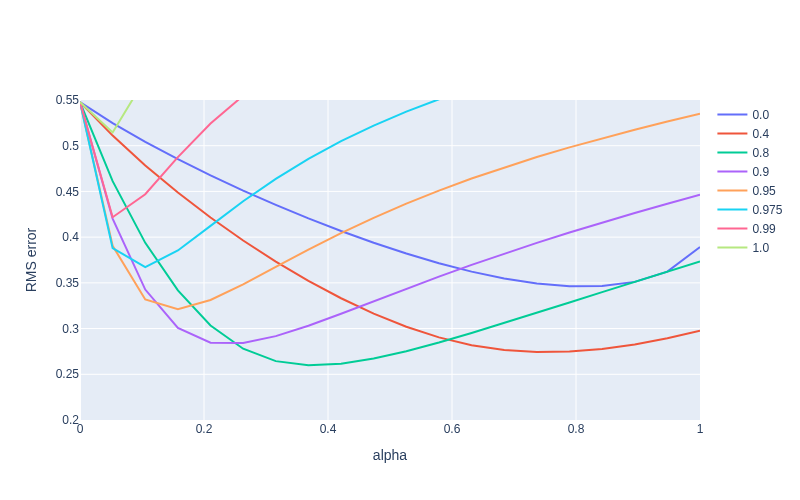

In [5]:
fig = go.Figure()
for l in lambdaList:
    fig.add_trace(go.Scatter(x=alphas, y=lambdaCurves[l], name=str(l)))
fig.update_layout(width=800, yaxis_title="RMS error", xaxis_title="alpha")
fig.update_yaxes(range=[0.2, 0.55])
fig.show()

## TD($\lambda$)

In [6]:
def semiGradientTDLambda(nEpisodes, vInit, policy, nStates=5, alpha=0.1, l=1, gamma=1, leftReward=0):
    V = vInit.copy()
    learningCurve = np.empty((nEpisodes, nStates))

    for episode in range(nEpisodes):
        currentSate = nStates // 2
        Z = np.zeros(nStates)
        terminal = False
        while not terminal:
            currentAction = np.random.choice([-1, 1], p=policy[currentSate])
            reward = 0
            if currentSate == nStates - 1 and currentAction == 1:
                terminal = True
                reward = 1
                vNextState = 0
            elif currentSate == 0 and currentAction == -1:
                terminal = True
                reward = leftReward
                vNextState = 0
            else:
                vNextState = V[currentSate + currentAction]
            

            Z = gamma * l * Z
            Z[currentSate] += 1
            delta = reward + gamma * vNextState - V[currentSate]
            V += alpha * delta * Z
            currentSate += currentAction

        learningCurve[episode] = V.copy()

    trueValue = np.arange(1, nStates + 1) / (nStates + 1) + leftReward * (1 - np.arange(1, nStates + 1) / (nStates + 1))
    error = np.mean(np.sqrt(np.mean((learningCurve - trueValue) ** 2, axis=1)))
    return error

In [7]:
nStates = 19
leftReward = -1
nEpisodes = 10
nReps = 100
lambdaList = np.array([0, 0.4, 0.8, 0.9, 0.95, 0.975, 0.99, 1])
alphas = {0: np.linspace(0, 1, 50), 0.4: np.linspace(0, 1, 50), 0.8: np.linspace(0, 1, 50), 0.9: np.linspace(0, 0.6, 50), 
          0.95: np.linspace(0, 0.4, 50), 0.975: np.linspace(0, 0.25, 50), 0.99: np.linspace(0, 0.1, 50), 1: np.linspace(0, 0.1, 50)}
vInitVRW = np.zeros(nStates)
policy = 0.5 * np.ones((nStates, 2))

lambdaCurvesTDLambda = {}
for l in lambdaList:
    lambdaErrors = []
    for alpha in alphas[l]:
        lambdaAlphaErrors = []
        for rep in range(nReps):
            lambdaAlphaErrors.append(semiGradientTDLambda(nEpisodes, vInitVRW, policy, nStates=nStates, alpha=alpha, l=l, gamma=1, leftReward=leftReward))
        lambdaErrors.append(np.mean(lambdaAlphaErrors))
    lambdaCurvesTDLambda[l] = lambdaErrors

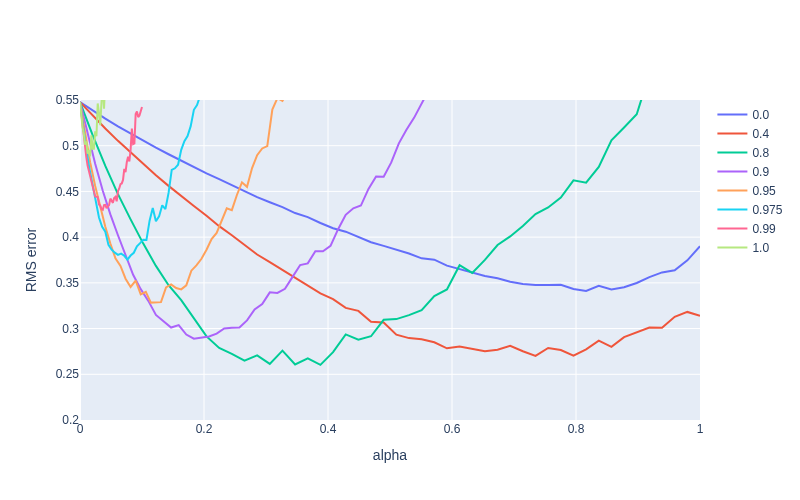

In [8]:
fig = go.Figure()
for l in lambdaList:
    fig.add_trace(go.Scatter(x=alphas[l], y=lambdaCurvesTDLambda[l], name=str(l)))
fig.update_layout(width=800, yaxis_title="RMS error", xaxis_title="alpha")
fig.update_yaxes(range=[0.2, 0.55])
fig.show()

## True Online TD($\lambda$)

In [9]:
def onlineTDLambda(nEpisodes, vInit, policy, nStates=5, alpha=0.1, l=1, gamma=1, leftReward=0):
    V = vInit.copy()
    learningCurve = np.empty((nEpisodes, nStates))

    for episode in range(nEpisodes):
        currentState = nStates // 2
        Z = np.zeros(nStates)
        vOld = 0
        terminal = False
        while not terminal:
            currentAction = np.random.choice([-1, 1], p=policy[currentState])
            reward = 0
            if currentState == nStates - 1 and currentAction == 1:
                terminal = True
                reward = 1
                vNextState = 0
            elif currentState == 0 and currentAction == -1:
                terminal = True
                reward = leftReward
                vNextState = 0
            else:
                vNextState = V[currentState + currentAction]
            
            vCurrentState = V[currentState]
            delta = reward + gamma * vNextState - vCurrentState
            zCurrentState = Z[currentState]
            Z = gamma * l * Z
            Z[currentState] += 1 - alpha * gamma * l * zCurrentState
            V += alpha * (delta + vCurrentState - vOld) * Z
            V[currentState] -= alpha * (vCurrentState - vOld)
            vOld = vNextState
            currentState += currentAction

        learningCurve[episode] = V.copy()

    trueValue = np.arange(1, nStates + 1) / (nStates + 1) + leftReward * (1 - np.arange(1, nStates + 1) / (nStates + 1))
    error = np.mean(np.sqrt(np.mean((learningCurve - trueValue) ** 2, axis=1)))
    return error

In [10]:
nStates = 19
leftReward = -1
nEpisodes = 10
nReps = 100
lambdaList = np.array([0, 0.4, 0.8, 0.9, 0.95, 0.975, 0.99, 1])
alphas = {0: np.linspace(0, 1, 50), 0.4: np.linspace(0, 1, 50), 0.8: np.linspace(0, 1, 50), 0.9: np.linspace(0, 1, 50), 
          0.95: np.linspace(0, 1, 50), 0.975: np.linspace(0, 1, 50), 0.99: np.linspace(0, 0.5, 50), 1: np.linspace(0, 0.2, 50)}
vInitVRW = np.zeros(nStates)
policy = 0.5 * np.ones((nStates, 2))

lambdaCurvesOnlineTDLambda = {}
for l in lambdaList:
    lambdaErrors = []
    for alpha in alphas[l]:
        lambdaAlphaErrors = []
        for rep in range(nReps):
            lambdaAlphaErrors.append(onlineTDLambda(nEpisodes, vInitVRW, policy, nStates=nStates, alpha=alpha, l=l, gamma=1, leftReward=leftReward))
        lambdaErrors.append(np.mean(lambdaAlphaErrors))
    lambdaCurvesOnlineTDLambda[l] = lambdaErrors

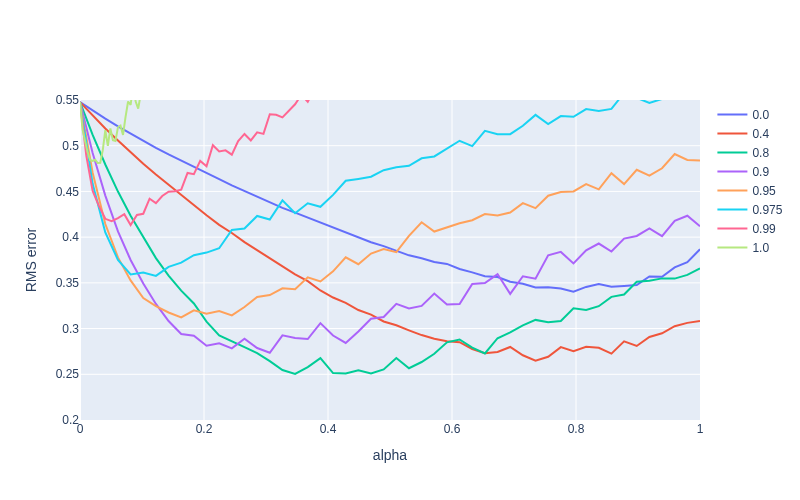

In [11]:
fig = go.Figure()
for l in lambdaList:
    fig.add_trace(go.Scatter(x=alphas[l], y=lambdaCurvesOnlineTDLambda[l], name=str(l)))
fig.update_layout(width=800, yaxis_title="RMS error", xaxis_title="alpha")
fig.update_yaxes(range=[0.2, 0.55])
fig.show()

# Mountain Car

## Sarsa($\lambda$)

In [5]:
def identifyTile(x, y, nTiles, i, a, b, c, d, ox=3, oy=1):
    omegaX = (b - a) / nTiles
    omegaY = (d - c) / nTiles
    k = math.ceil((x - a) / omegaX - ((i * ox) % nTiles) / nTiles)
    l = math.ceil((y - c) / omegaY - ((i * oy) % nTiles) / nTiles)

    if i == 0:
        k = max(k, 1)
        l = max(l, 1)
    return k, l

In [4]:
def computeQ(position, velocity, Wr, Wz, Wf, nTilings, a, b, c, d):
    tiles = tuple(np.array([(i, *identifyTile(position, velocity, nTilings, i, a, b, c, d)) for i in range(nTilings)]).T)
    return Wr[tiles].sum(), Wz[tiles].sum(), Wf[tiles].sum()

In [6]:
def sarsaLambdaMC(nEpisodes, alpha, epsilon, l, traces="replacing", nTilings=8, a=-1.2, b=0.5, c=-0.07, d=0.07, ls=-0.6, us=-0.4):
    Wreverse = np.zeros((nTilings, nTilings + 1, nTilings + 1))
    Wforward = np.zeros((nTilings, nTilings + 1, nTilings + 1))
    Wzero = np.zeros((nTilings, nTilings + 1, nTilings + 1))

    nSteps = np.empty(nEpisodes, dtype=int)

    for episode in range(nEpisodes):
        stepCount = 0
        currentPosition = ls + (us - ls) * np.random.rand()
        currentVelocity = 0
        qCurrentState = computeQ(currentPosition, currentVelocity, Wreverse, Wzero, Wforward, nTilings, a, b, c, d)
        if np.random.rand() < epsilon:
            currentAction = np.random.choice([-1, 0, 1])
        else:
            qMax = np.max(qCurrentState)
            currentAction = np.random.choice([action for action in [-1, 0, 1] if qCurrentState[action + 1] == qMax])
        
        terminal = False
        traceReverse = np.zeros(Wreverse.shape)
        traceForward = np.zeros(Wforward.shape)
        traceZero = np.zeros(Wzero.shape)
        while not terminal:
            nextVelocity = min(max(c, currentVelocity + 0.001 * currentAction - 0.0025 * np.cos(3 * currentPosition)), d)
            nextPosition = min(max(a, currentPosition + nextVelocity), b)
            stepCount += 1

            R = -1
            if nextPosition == a:
                nextVelocity = 0

            elif nextPosition == b:
                terminal = True

            delta = R
            if traces == "clearing":
                traceReverse = np.zeros(Wreverse.shape)
                traceZero = np.zeros(Wzero.shape)
                traceForward = np.zeros(Wforward.shape)
            for tiling in range(nTilings):
                currentTile = identifyTile(currentPosition, currentVelocity, nTilings, tiling, a, b, c, d)
                if currentAction == -1:
                    delta -= Wreverse[tiling][currentTile]
                    if traces == "replacing" or traces == "clearing":
                        traceReverse[tiling][currentTile] = 1
                    elif traces == "accumulating":
                        traceReverse[tiling][currentTile] += 1
                elif currentAction == 0:
                    delta -= Wzero[tiling][currentTile]
                    if traces == "replacing" or traces == "clearing":
                        traceZero[tiling][currentTile] = 1
                    elif traces == "accumulating":
                        traceZero[tiling][currentTile] += 1
                else:
                    delta -= Wforward[tiling][currentTile]
                    if traces == "replacing" or traces == "clearing":
                        traceForward[tiling][currentTile] = 1
                    elif traces == "accumulating":
                        traceForward[tiling][currentTile] += 1

            if terminal:
                Wreverse += alpha * delta * traceReverse
                Wzero += alpha * delta * traceZero
                Wforward += alpha * delta * traceForward
                break
                
            qNextState = computeQ(nextPosition, nextVelocity, Wreverse, Wzero, Wforward, nTilings, a, b, c, d)
            if np.random.rand() < epsilon:
                nextAction = np.random.choice([-1, 0, 1])
            else:
                qMax = np.max(qNextState)
                nextAction = np.random.choice([action for action in [-1, 0, 1] if qNextState[action + 1] == qMax])
            
            for tiling in range(nTilings):
                nextTile = identifyTile(nextPosition, nextVelocity, nTilings, tiling, a, b, c, d)
                if nextAction == -1:
                    delta += Wreverse[tiling][nextTile]
                elif nextAction == 0:
                    delta += Wzero[tiling][nextTile]
                else:
                    delta += Wforward[tiling][nextTile]

            Wreverse += alpha * delta * traceReverse
            Wzero += alpha * delta * traceZero
            Wforward += alpha * delta * traceForward

            traceReverse *= l
            traceZero *= l
            traceForward *= l

        
            currentPosition = nextPosition
            currentVelocity = nextVelocity
            currentAction = nextAction

            if stepCount >= 1000:
                break
        nSteps[episode] = stepCount

    return nSteps
    

In [15]:
nEpisodes = 50
nReps = 100
lambdaList = np.array([0, 0.68, 0.84, 0.92, 0.94, 0.98, 0.99])
alphas = np.arange(0.2, 2, 0.1)

avgsSarsaLambdaReplacing = {}
for l in lambdaList:
    avgsSarsaLambdaReplacing[l] = []
    for alpha in alphas:
        nAlphaSteps = []
        for rep in range(nReps):
            nAlphaSteps.append(np.mean(sarsaLambdaMC(nEpisodes, alpha / 8, 0.01, l)))
        avgsSarsaLambdaReplacing[l].append(np.mean(nAlphaSteps))

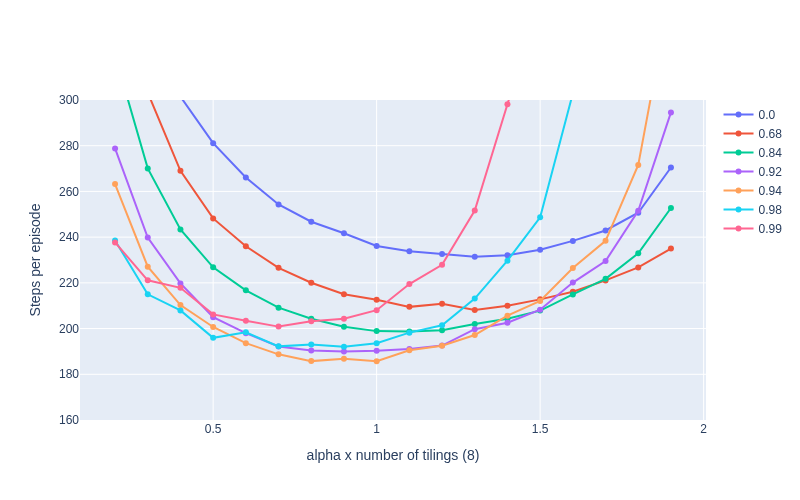

In [17]:
fig = go.Figure()
for l in lambdaList:
    fig.add_trace(go.Scatter(x=alphas, 
                             y=avgsSarsaLambdaReplacing[l], name=str(l)))
fig.update_layout(width=800, yaxis_title="Steps per episode", xaxis_title="alpha x number of tilings (8)")
fig.update_yaxes(range=[160, 300])
fig.show()

## True Online Sarsa($\lambda$)

In [7]:
def trueOnlineSarsaLambdaMC(nEpisodes, alpha, epsilon, l, nTilings=8, a=-1.2, b=0.5, c=-0.07, d=0.07, ls=-0.6, us=-0.4):
    Wreverse = np.zeros((nTilings, nTilings + 1, nTilings + 1))
    Wforward = np.zeros((nTilings, nTilings + 1, nTilings + 1))
    Wzero = np.zeros((nTilings, nTilings + 1, nTilings + 1))

    nSteps = np.empty(nEpisodes, dtype=int)

    for episode in range(nEpisodes):
        stepCount = 0
        currentPosition = ls + (us - ls) * np.random.rand()
        currentVelocity = 0
        qCurrentState = computeQ(currentPosition, currentVelocity, Wreverse, Wzero, Wforward, nTilings, a, b, c, d)
        if np.random.rand() < epsilon:
            currentAction = np.random.choice([-1, 0, 1])
        else:
            qMax = np.max(qCurrentState)
            currentAction = np.random.choice([action for action in [-1, 0, 1] if qCurrentState[action + 1] == qMax])
        
        terminal = False
        traceReverse = np.zeros(Wreverse.shape)
        traceForward = np.zeros(Wforward.shape)
        traceZero = np.zeros(Wzero.shape)
        qOld = 0
        while not terminal:
            qCurrentStateAction = qCurrentState[currentAction + 1]
            nextVelocity = min(max(c, currentVelocity + 0.001 * currentAction - 0.0025 * np.cos(3 * currentPosition)), d)
            nextPosition = min(max(a, currentPosition + nextVelocity), b)
            stepCount += 1

            R = -1.
            if nextPosition == a:
                nextVelocity = 0

            elif nextPosition == b:
                terminal = True
                qNextStateAction = 0

            if not terminal:
                qNextState = computeQ(nextPosition, nextVelocity, Wreverse, Wzero, Wforward, nTilings, a, b, c, d)
                if np.random.rand() < epsilon:
                    nextAction = np.random.choice([-1, 0, 1])
                else:
                    qMax = np.max(qNextState)
                    nextAction = np.random.choice([action for action in [-1, 0, 1] if qNextState[action + 1] == qMax])
                qNextStateAction = qNextState[nextAction + 1]
                    

            delta = R + qNextStateAction - qCurrentStateAction
            zTx = 0
            for tiling in range(nTilings):
                currentTile = identifyTile(currentPosition, currentVelocity, nTilings, tiling, a, b, c, d)
                if currentAction == -1:
                    zTx += traceReverse[tiling][currentTile]
                elif currentAction == 0:
                    zTx += traceZero[tiling][currentTile]
                else:
                    zTx += traceForward[tiling][currentTile]

            traceReverse *= l
            traceZero *= l
            traceForward *= l
            for tiling in range(nTilings):
                currentTile = identifyTile(currentPosition, currentVelocity, nTilings, tiling, a, b, c , d)
                if currentAction == -1:
                    traceReverse[tiling][currentTile] += 1 - alpha * l * zTx
                    Wreverse[tiling][currentTile] -= alpha * (qCurrentStateAction - qOld)
                elif currentAction == 0:
                    traceZero[tiling][currentTile] += 1 - alpha * l * zTx
                    Wzero[tiling][currentTile] -= alpha * (qCurrentStateAction - qOld)
                else:
                    traceForward[tiling][currentTile] += 1 - alpha * l * zTx
                    Wforward[tiling][currentTile] -= alpha * (qCurrentStateAction - qOld)

            Wreverse += alpha * (delta + qCurrentStateAction - qOld) * traceReverse
            Wzero += alpha * (delta + qCurrentStateAction - qOld) * traceZero
            Wforward += alpha * (delta + qCurrentStateAction - qOld) * traceForward

            if not terminal:
                currentPosition = nextPosition
                currentVelocity = nextVelocity
                currentAction = nextAction
                qOld = qNextStateAction
                qCurrentState = computeQ(currentPosition, currentVelocity, Wreverse, Wzero, Wforward, nTilings, a, b, c, d)

            if stepCount >= 1000:
                break
        
        nSteps[episode] = stepCount

    return nSteps

In [9]:
nEpisodes = 20
nReps = 100
alphas = np.arange(0.2, 2, 0.1)
l = 0.92

avgsTrueOnlineSarsa = []
avgsSarsaLambdaReplacing = []
avgsSarsaLambdaClearing = []
avgsSarsaLambdaAccumulating = []
for alpha in alphas:
    nAlphaStepsTrueOnlineSarsa = []
    nAlphaStepsSarsaLambdaReplacing = []
    nAlphaStepsSarsaLambdaClearing = []
    nAlphaStepsSarsaLambdaAccumulating = []
    for rep in range(nReps):
        nAlphaStepsTrueOnlineSarsa.append(np.mean(trueOnlineSarsaLambdaMC(nEpisodes, alpha / 8, 0, l)))
        nAlphaStepsSarsaLambdaReplacing.append(np.mean(sarsaLambdaMC(nEpisodes, alpha / 8, 0.01, l, traces="replacing")))
        nAlphaStepsSarsaLambdaClearing.append(np.mean(sarsaLambdaMC(nEpisodes, alpha / 8, 0.01, l, traces="clearing")))
        # nAlphaStepsSarsaLambdaAccumulating.append(np.mean(sarsaLambdaMC(nEpisodes, alpha / 8, 0.01, l, traces="accumulating")))
    avgsTrueOnlineSarsa.append(-np.mean(nAlphaStepsTrueOnlineSarsa))
    avgsSarsaLambdaReplacing.append(-np.mean(nAlphaStepsSarsaLambdaReplacing))
    avgsSarsaLambdaClearing.append(-np.mean(nAlphaStepsSarsaLambdaClearing))
    avgsSarsaLambdaAccumulating.append(-np.mean(nAlphaStepsSarsaLambdaAccumulating))

/home/e61685/.pyenv/versions/python_knitro/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/e61685/.pyenv/versions/python_knitro/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


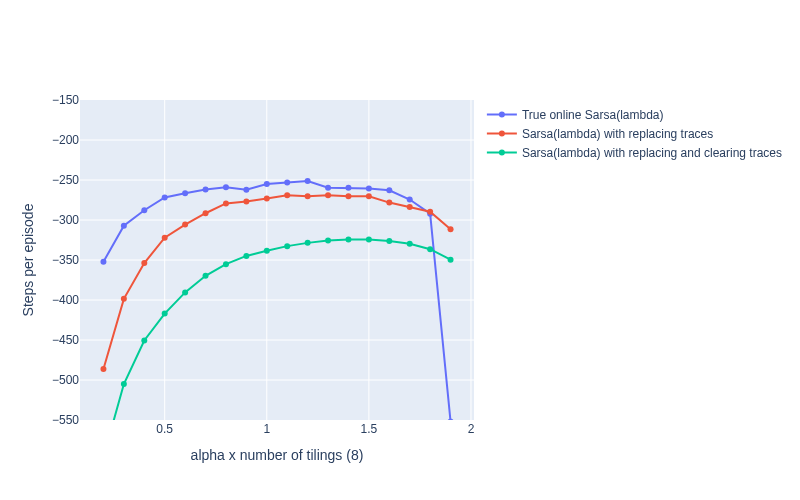

In [10]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=alphas, y=avgsTrueOnlineSarsa, name="True online Sarsa(lambda)"))
fig.add_trace(go.Scatter(x=alphas, y=avgsSarsaLambdaReplacing, name="Sarsa(lambda) with replacing traces"))
fig.add_trace(go.Scatter(x=alphas, y=avgsSarsaLambdaClearing, name="Sarsa(lambda) with replacing and clearing traces"))
# fig.add_trace(go.Scatter(x=alphas, y=avgsSarsaLambdaAccumulating, name="Sarsa(lambda) with accumulating traces"))
fig.update_layout(width=800, yaxis_title="Steps per episode", xaxis_title="alpha x number of tilings (8)")
fig.update_yaxes(range=[-550, -150])
fig.show()